# 07b2 · 80% end-of-life alert patch (phase 7b2)
Corrects the 80% EOL truth definition used in 07b (life field `cycle_life_final`, not a `y <= 80` crossing). No training. Batch 3 is spent: its labels are descriptive only and nothing is chosen with them. The 7b outputs and `monitor_config.json` are read-only; the addendum is frozen and logged before any 80% alert metric is computed. Writes only inside `outputs/phase7b2`.

In [1]:
# S0a environment (uv)
import importlib.util, shutil, subprocess, sys
NEED = {"numpy": "numpy", "pandas": "pandas", "pyarrow": "pyarrow", "scipy": "scipy", "matplotlib": "matplotlib", "torch": "torch"}
_missing = [pkg for mod, pkg in NEED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    _uv = shutil.which("uv")
    if _uv is None: raise RuntimeError("uv not found on PATH; install uv (https://docs.astral.sh/uv/) and rerun")
    subprocess.run([_uv, "pip", "install", "--python", sys.executable, *_missing], check=True)
    print("installed with uv:", _missing)
else:
    print("all packages present; nothing to install")

all packages present; nothing to install


**S0** setup, hash guards, 7b log chain, config, predictions

In [2]:
# S0 setup
SMOKE = False   # True: 8 batch-3 cells, writes to outputs/phase7b2/smoke/. Never quote smoke results.
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import sys, json, hashlib, time, platform, warnings, re, textwrap, datetime as dt
sys.dont_write_bytecode = True
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import pyarrow.dataset as pds
from scipy.signal import lfilter

T0 = time.time(); SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

_cwd = Path.cwd().resolve()
_cands = [_cwd, *_cwd.parents, Path(r"C:\workstation\3RD YEAR\Battery-Health-Estimation")]
ROOT = next((p for p in _cands if (p / "notebooks").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise RuntimeError(f"project root not found: no folder in {_cwd}, its parents or the stated project path contains both notebooks/ and data/")
OUT = ROOT / "outputs" / "phase7b2" / ("smoke" if SMOKE else "")
OUT.mkdir(parents=True, exist_ok=True)
P7A, P7B = ROOT / "outputs" / "phase7a", ROOT / "outputs" / "phase7b"
DP = ROOT / "data" / "processed"
LOG_PATH = OUT / "phase7b2_log.jsonl"
WINDOWS = ["W300", "W240"]

def sha256_bytes(b): return hashlib.sha256(b).hexdigest()
def sha256_file(p): return sha256_bytes(Path(p).read_bytes())
def now_utc(): return dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
def _jd(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o))
def W(path):
    p = Path(path).resolve()
    if p != OUT.resolve() and OUT.resolve() not in p.parents:
        raise PermissionError(f"write refused (outside {OUT}): {p}")
    p.parent.mkdir(parents=True, exist_ok=True)
    return p
def write_text(path, text): W(path).write_text(text, encoding="utf-8", newline="\n")
def write_json(path, obj): write_text(path, json.dumps(obj, indent=2, sort_keys=True, default=_jd) + "\n")
def write_once(path, text):
    # write-once file: create it, or confirm the stored text is identical
    p = Path(path)
    if p.exists(): return p.read_text(encoding="utf-8") == text
    with open(W(p), "x", encoding="utf-8", newline="\n") as f: f.write(text)
    return True

CHECKS, EXTRA = [], {}
class CheckFail(RuntimeError): pass
def dump_report(failed=None):
    n = {k: sum(c["status"] == k for c in CHECKS) for k in ("PASS", "WARN", "FAIL")}
    write_json(OUT / "verification_report.json", dict(created_utc=now_utc(), smoke=SMOKE, failed=failed, summary=n, checks=CHECKS, extra=EXTRA, elapsed_s=round(time.time() - T0, 1)))
    return n
def check(name, ok, detail="", warn_only=False):
    ok = bool(ok)
    status = "PASS" if ok else ("WARN" if warn_only else "FAIL")
    CHECKS.append(dict(name=name, status=status, detail=str(detail)))
    print(f"[{status}] {name}" + (f" - {detail}" if str(detail) else ""))
    if status == "FAIL":
        dump_report(failed=name)
        raise CheckFail(f"{name}: {detail}")

# report blocks: every table printed through show() and every note() goes into the report, in order
BLOCKS, TABLES, EXTRA_CSV = [], {}, {}
def tx(df, nd=3): return df.to_string(index=False, float_format=lambda v: f"{v:.{nd}f}")
def show(df, title, name=None, nd=3):
    head, body = f"{title}  (n={len(df)} rows)", tx(df, nd)
    print("\n" + head); print(body)
    BLOCKS.append(dict(kind="table", title=title, text=head + "\n" + body))
    if name: TABLES[name] = df
    return df
def note(title, text):
    print(f"\n{title}\n{text}")
    BLOCKS.append(dict(kind="text", title=title, text=f"{title}\n{text}"))

# append-only log with hash chain (same scheme as 7b)
def _log_lines():
    return [l for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()] if LOG_PATH.exists() else []
def log_entries(): return [json.loads(l) for l in _log_lines()]
def log_has(ev): return any(e["event"] == ev for e in log_entries())
def log_append(event, **kw):
    assert event in ("start", "addendum_frozen", "done")
    ls = _log_lines()
    prev = sha256_bytes(ls[-1].encode("utf-8")) if ls else ""
    entry = dict(t_utc=now_utc(), event=event, prev_line_sha256=prev, smoke=SMOKE, **kw)
    with open(W(LOG_PATH), "a", encoding="utf-8", newline="\n") as f:
        f.write(json.dumps(entry, sort_keys=True, default=_jd) + "\n")
    return entry

# environment
print(f"torch {torch.__version__} | python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | SMOKE={SMOKE}")
cuda = torch.cuda.is_available()
cuda_name = torch.cuda.get_device_name(0) if cuda else "none"
print(f"CUDA available: {cuda} | device: {cuda_name}")
check("CUDA available", cuda, f"torch {torch.__version__}, torch.cuda.is_available() = {cuda}, device {cuda_name}; this notebook needs no GPU", warn_only=True)
print("ROOT:", ROOT, "| OUT:", OUT)

torch 2.14.1+cu130 | python 3.13.13 | numpy 2.5.4 | pandas 3.1.0 | SMOKE=False
CUDA available: True | device: NVIDIA GeForce RTX 3050 6GB Laptop GPU
[PASS] CUDA available - torch 2.14.1+cu130, torch.cuda.is_available() = True, device NVIDIA GeForce RTX 3050 6GB Laptop GPU; this notebook needs no GPU
ROOT: C:\workstation\3RD YEAR\Battery-Health-Estimation | OUT: C:\workstation\3RD YEAR\Battery-Health-Estimation\outputs\phase7b2


In [3]:
# S0 integrity: hash guards, 7b log chain, config, predictions
FROZEN = {
    "monitor_config":     (P7B / "monitor_config.json", "638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2"),
    "preregistration":    (P7A / "preregistration.json", "11f9741387cb001ef55aa8459e4857ab70871e89cd03e7cce318043be41c8bce"),
    "batch3_predictions": (P7A / "batch3_predictions.parquet", "679ec76862de63f2615a710c7fc1f3ca2ec6c01149735bdd909b95ad5a9c7acd"),
    "batch3_verdict":     (P7A / "batch3_verdict.json", "57a054bdf25243d3b9e0aced2c0c245135da2c769b2d1e635d329b742fc4deb8"),
    "model_M0_W240":      (P7A / "models" / "M0_W240.npz", "29cd3ec8c5c2113db1d1b3562365461f3045f07b5e3113532f28eeff34c744fe"),
    "model_M0_W300":      (P7A / "models" / "M0_W300.npz", "06f63dc6c5a89750d18622099961e875ee1aeb1b65d9afe16b556f0d7cb149c2"),
}
def verify_frozen(tag):
    res = {}
    for k, (p, h) in FROZEN.items():
        if not p.exists(): check(f"[{tag}] sha256 {k}", False, f"file missing: {p}")
        got = sha256_file(p)
        res[k] = dict(path=str(p.relative_to(ROOT)), expected=h, got=got)
        check(f"[{tag}] sha256 {k}", got == h, f"{p.name}: got {got[:16]}... expected {h[:16]}...")
    return res
HASHES_START = verify_frozen("start")
CFG_PATH = FROZEN["monitor_config"][0]; CFG_SHA = HASHES_START["monitor_config"]["got"]
CFG = json.loads(CFG_PATH.read_text(encoding="utf-8"))

# 7b log chain: events and prev_line_sha256
_l7 = P7B / "phase7b_log.jsonl"
if not _l7.exists(): raise FileNotFoundError(f"7b log missing: {_l7}")
_lines7 = [l for l in _l7.read_text(encoding="utf-8").splitlines() if l.strip()]
_ev7 = [json.loads(l) for l in _lines7]
_want = ["start", "start", "config_frozen", "labels_loaded", "done"]
check("7b log: events start, start, config_frozen, labels_loaded, done", [e["event"] for e in _ev7] == _want, f"found {[e['event'] for e in _ev7]}")
_ch7 = [(_ev7[i]["prev_line_sha256"] == (sha256_bytes(_lines7[i - 1].encode("utf-8")) if i else "")) for i in range(len(_ev7))]
check("7b log: prev_line_sha256 equals SHA-256 of the previous raw line", all(_ch7), f"{sum(_ch7)} of {len(_ch7)} links valid")
_cf7 = [e for e in _ev7 if e["event"] == "config_frozen"][0]
check("7b log: logged config hash equals monitor_config.json", _cf7.get("monitor_config_sha256") == CFG_SHA, f"logged {str(_cf7.get('monitor_config_sha256'))[:16]}..., file {CFG_SHA[:16]}...")

# config: alpha and conformal tables are read, never recomputed
ALPHA = dict(CFG["ema"]["chosen"])
check("config: EMA alpha is 0.3 at both windows", ALPHA == {"W300": 0.3, "W240": 0.3}, f"alpha {ALPHA}")
_fr = CFG["frozen_reference_hashes"]
_pairs = [("preregistration", "preregistration"), ("batch3_predictions", "batch3_predictions"), ("batch3_verdict", "batch3_verdict"), ("model_M0_W240", "model_M0_W240"), ("model_M0_W300", "model_M0_W300")]
check("config: embedded reference hashes equal the guarded hashes", all(_fr[a] == FROZEN[b][1] for a, b in _pairs), f"{sum(_fr[a] == FROZEN[b][1] for a, b in _pairs)} of {len(_pairs)} agree")
CT = CFG["conformal"]["tables"]
_COLS = {"pred_hi", "ql_pooled", "q2_pooled", "ql_cellbal", "q2_cellbal"}
for w in WINDOWS:
    for s in ("raw", "ema"):
        t = CT[w][s]; bins = sorted(t["bins"], key=lambda r: r["bin"]); ed = t["inner_edges"]
        ok = (len(bins) == len(ed) + 1 and all(_COLS <= set(r) for r in bins) and [r["pred_hi"] for r in bins[:-1]] == ed and bins[-1]["pred_hi"] is None and ed == sorted(ed))
        check(f"config: {w} {s} conformal table is well formed", ok, f"{len(bins)} bins, {len(ed)} inner edges, pred_hi equals inner_edges: {[r['pred_hi'] for r in bins[:-1]] == ed}")
def conf_lookup(w, kind, est, variant="pooled"):
    # bin(estimate) = number of inner edges <= estimate (searchsorted side='right'); lower = est - ql[bin]; interval = est +/- q2[bin]
    t = CT[w][kind]; bins = sorted(t["bins"], key=lambda r: r["bin"]); b = np.searchsorted(t["inner_edges"], est, side="right")
    ql = np.array([r[f"ql_{variant}"] for r in bins])[b]; q2 = np.array([r[f"q2_{variant}"] for r in bins])[b]
    return est - q2, est + q2, est - ql

# batch-3 predictions (M0 only is used)
PRED = pd.read_parquet(P7A / "batch3_predictions.parquet")
check("predictions have the expected columns", {"model", "window", "seed", "row_id", "cell_id", "pred_pp"} <= set(PRED.columns), f"columns {list(PRED.columns)}")
PM0 = PRED[PRED.model.astype(str) == "M0"]
check("predictions: M0 present at both windows", set(PM0.window.astype(str)) == set(WINDOWS), f"M0 windows {sorted(set(PM0.window.astype(str)))}, {len(PM0):,} rows")
_ns = PM0.groupby(["window", "row_id"]).seed.nunique()
check("predictions: M0 has 5 seeds per row, no NaN", (_ns == 5).all() and PM0.pred_pp.notna().all(), f"seeds per row min {_ns.min()} max {_ns.max()}, NaN {int(PM0.pred_pp.isna().sum())}")
check("predictions: no duplicate keys", not PM0.duplicated(["window", "seed", "row_id"]).any(), f"{PM0.row_id.nunique():,} unique M0 row_ids")
log_append("start", hashes={k: v["got"] for k, v in HASHES_START.items()}, log_7b_events=[e["event"] for e in _ev7], monitor_config_sha256=CFG_SHA)

[PASS] [start] sha256 monitor_config - monitor_config.json: got 638b6c3a6ad31c69... expected 638b6c3a6ad31c69...
[PASS] [start] sha256 preregistration - preregistration.json: got 11f9741387cb001e... expected 11f9741387cb001e...
[PASS] [start] sha256 batch3_predictions - batch3_predictions.parquet: got 679ec76862de63f2... expected 679ec76862de63f2...
[PASS] [start] sha256 batch3_verdict - batch3_verdict.json: got 57a054bdf25243d3... expected 57a054bdf25243d3...
[PASS] [start] sha256 model_M0_W240 - M0_W240.npz: got 29cd3ec8c5c2113d... expected 29cd3ec8c5c2113d...
[PASS] [start] sha256 model_M0_W300 - M0_W300.npz: got 06f63dc6c5a89750... expected 06f63dc6c5a89750...
[PASS] 7b log: events start, start, config_frozen, labels_loaded, done - found ['start', 'start', 'config_frozen', 'labels_loaded', 'done']
[PASS] 7b log: prev_line_sha256 equals SHA-256 of the previous raw line - 5 of 5 links valid
[PASS] 7b log: logged config hash equals monitor_config.json - logged 638b6c3a6ad31c69..., fil

{'t_utc': '2026-11-05T04:59:05+00:00',
 'event': 'start',
 'prev_line_sha256': '',
 'smoke': False,
 'hashes': {'monitor_config': '638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2',
  'preregistration': '11f9741387cb001ef55aa8459e4857ab70871e89cd03e7cce318043be41c8bce',
  'batch3_predictions': '679ec76862de63f2615a710c7fc1f3ca2ec6c01149735bdd909b95ad5a9c7acd',
  'batch3_verdict': '57a054bdf25243d3b9e0aced2c0c245135da2c769b2d1e635d329b742fc4deb8',
  'model_M0_W240': '29cd3ec8c5c2113db1d1b3562365461f3045f07b5e3113532f28eeff34c744fe',
  'model_M0_W300': '06f63dc6c5a89750d18622099961e875ee1aeb1b65d9afe16b556f0d7cb149c2'},
 'log_7b_events': ['start', 'start', 'config_frozen', 'labels_loaded', 'done'],
 'monitor_config_sha256': '638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2'}

**S1** life column: `cycle_life_field` vs `cycle_life_final`

In [4]:
# S1 life column: cycle_life_field vs cycle_life_final
def find_one(name, dirs):
    for d in dirs:
        if (d / name).exists(): return d / name
    hits = [p for p in ROOT.rglob(name) if ".venv" not in p.parts]
    if hits: return hits[0]
    raise FileNotFoundError(f"{name} not found under {[str(d) for d in dirs]} or anywhere below {ROOT}")
REG_PATH = find_one("cell_registry_final.csv", [DP, ROOT / "outputs/phase3"])
REG = pd.read_csv(REG_PATH)
print("registry", REG_PATH.relative_to(ROOT), "| columns", list(REG.columns), "| shape", REG.shape)
for c in ("cell_id", "cycle_life_field", "cycle_life_final"):
    check(f"registry has column {c}", c in REG.columns, f"columns {list(REG.columns)}")

# labels table (batch membership, scored mask, labels)
LAB_CANDS = sorted(DP.glob("labels_table*.parquet")) or sorted((ROOT / "outputs/phase3").glob("labels_table*.parquet"))
if not LAB_CANDS: raise FileNotFoundError("no labels_table*.parquet under data/processed or outputs/phase3")
LABELS_PATH = next((c for c in LAB_CANDS if c.stem == "labels_table_v2"), LAB_CANDS[-1])
_ds = pds.dataset(str(LABELS_PATH))
check("label table has needed columns", {"row_id", "cell_id", "batch", "cycle_number", "soh_nom", "scored2"} <= set(_ds.schema.names), f"{LABELS_PATH.name} columns {_ds.schema.names}")
def _bnum(v):
    if isinstance(v, (int, float, np.integer, np.floating)): return int(v)
    m = re.search(r"\d+", str(v)); return int(m.group()) if m else -1
lab0 = _ds.to_table(columns=["row_id", "cell_id", "batch", "cycle_number", "scored2"]).to_pandas()
check("labels: row_id equals row position", np.array_equal(lab0.row_id.values, np.arange(len(lab0))), f"{len(lab0):,} rows")
lab0["batch_i"] = lab0.batch.map(_bnum); lab0["scored2"] = lab0.scored2.astype(bool)
LAB_IDX = lab0.set_index("row_id")

# development out-of-fold predictions (phase 5b), M0 only
_ff = sorted((ROOT / "outputs/phase5b/cache").glob("final_*.parquet"))
if not _ff: raise FileNotFoundError("no outputs/phase5b/cache/final_*.parquet")
_parts = []
for f in _ff:
    t = pd.read_parquet(f); _parts.append(t[t.model.astype(str) == "M0"])
FIN = pd.concat(_parts, ignore_index=True); del _parts
print("5b final tables:", [f.name for f in _ff], "| M0 rows", f"{len(FIN):,}", "| repeats", sorted(FIN.repeat.unique()))
check("5b columns present", {"window", "model", "repeat", "seed", "row_id", "cell_id", "pred_pp"} <= set(FIN.columns), f"columns {list(FIN.columns)}")
check("5b contains M0 at both windows", all((FIN.window.astype(str) == w).any() for w in WINDOWS), f"windows {sorted(FIN.window.astype(str).unique())}")
DEV_CELLS = sorted(FIN.cell_id.unique()); B3_ALL = sorted(PM0.cell_id.unique())
check("84 development cells and 40 batch-3 cells", len(DEV_CELLS) == 84 and len(B3_ALL) == 40, f"{len(DEV_CELLS)} development, {len(B3_ALL)} batch-3")
check("development and batch-3 cells are disjoint", not (set(DEV_CELLS) & set(B3_ALL)), f"overlap {sorted(set(DEV_CELLS) & set(B3_ALL))}")
_bd = sorted(set(lab0.loc[lab0.cell_id.isin(DEV_CELLS), "batch_i"])); _bb = sorted(set(lab0.loc[lab0.cell_id.isin(B3_ALL), "batch_i"]))
check("batch-3 cells are batch 3 and development cells are batches 1 and 2", _bb == [3] and 3 not in _bd, f"development batches {_bd}, batch-3 batches {_bb}")

KEPT = DEV_CELLS + B3_ALL
_dup = REG.cell_id.duplicated().sum()
check(f"registry holds each of the {len(KEPT)} kept cells exactly once", set(KEPT) <= set(REG.cell_id) and REG[REG.cell_id.isin(KEPT)].cell_id.is_unique, f"{len(set(KEPT) & set(REG.cell_id))} of {len(KEPT)} found, duplicate cell_id rows in registry {int(_dup)}")
R = REG[REG.cell_id.isin(KEPT)].drop_duplicates("cell_id").set_index("cell_id").loc[KEPT]
CMP = pd.DataFrame(dict(cell_id=KEPT, group=["dev"] * len(DEV_CELLS) + ["b3"] * len(B3_ALL), cycle_life_field=R.cycle_life_field.astype(float).values, cycle_life_final=R.cycle_life_final.astype(float).values))
check("cycle_life_field and cycle_life_final are finite for all kept cells", np.isfinite(CMP[["cycle_life_field", "cycle_life_final"]].to_numpy()).all(), f"{len(CMP)} cells, NaN {int(CMP[['cycle_life_field', 'cycle_life_final']].isna().sum().sum())}")
CMP["diff_final_minus_field"] = CMP.cycle_life_final - CMP.cycle_life_field

# stitched flag from the registry (same detection as 7b)
_stitch_cols = [c for c in ("stitched_into", "has_continuation", "continuation_cell") if c in REG.columns] or [c for c in REG.columns if "stitch" in c.lower()]
_NO = ("", "nan", "none", "false", "0", "0.0", "<na>", "nat")
def _truthy(s): return s.map(lambda v: (v is not None) and str(v).strip().lower() not in _NO).astype(bool)
_st = np.logical_or.reduce([_truthy(REG[c]).values for c in _stitch_cols]) if _stitch_cols else np.zeros(len(REG), bool)
FLAGGED = set(REG.loc[_st, "cell_id"]) & set(DEV_CELLS)
DIFFERS = set(CMP.loc[CMP.diff_final_minus_field != 0, "cell_id"])
STITCHED = FLAGGED if _stitch_cols else DIFFERS
CMP["stitched"] = CMP.cell_id.isin(STITCHED)
show(CMP.groupby("group").agg(n_cells=("cell_id", "size"), n_differ=("diff_final_minus_field", lambda s: int((s != 0).sum())), max_abs_diff=("diff_final_minus_field", lambda s: float(s.abs().max()))).reset_index(),
     "S1a cycle_life_field vs cycle_life_final by group", "s1a_life_columns_by_group.csv")
show(CMP[CMP.diff_final_minus_field != 0].drop(columns="group").reset_index(drop=True), "S1b kept cells where cycle_life_field differs from cycle_life_final", "s1b_life_differences.csv")
_b3 = CMP[CMP.group == "b3"]
check("batch-3 cells: cycle_life_field equals cycle_life_final (all 40, not stitched)", (_b3.cycle_life_field == _b3.cycle_life_final).all() and len(_b3) == 40, f"{int((_b3.cycle_life_field == _b3.cycle_life_final).sum())} of {len(_b3)} equal, max abs diff {_b3.diff_final_minus_field.abs().max():.1f}")
check("differences only for development cells", DIFFERS <= set(DEV_CELLS), f"{len(DIFFERS)} differing cells, {len(DIFFERS - set(DEV_CELLS))} of them outside development: {sorted(DIFFERS - set(DEV_CELLS))}")
check("exactly five cells differ", len(DIFFERS) == 5, f"{len(DIFFERS)} differing cells: {sorted(DIFFERS)}", warn_only=True)
check("the differing cells are the registry-flagged stitched cells", (not _stitch_cols) or DIFFERS == FLAGGED, f"flag columns {_stitch_cols}; differing {sorted(DIFFERS)}; flagged {sorted(FLAGGED)}", warn_only=True)
check("final life exceeds the field value for every differing cell", bool((CMP.loc[CMP.cell_id.isin(DIFFERS), "diff_final_minus_field"] > 0).all()), f"differences {CMP.loc[CMP.cell_id.isin(DIFFERS), 'diff_final_minus_field'].astype(int).tolist()}", warn_only=True)

LIFE = dict(zip(CMP.cell_id, CMP.cycle_life_final)); LIFE_FIELD = dict(zip(CMP.cell_id, CMP.cycle_life_field));
_dl = CMP[(CMP.group == "dev") & (CMP.cycle_life_final > 1434)].sort_values("cycle_life_final")
show(_dl[["cell_id", "cycle_life_field", "cycle_life_final", "stitched"]].reset_index(drop=True), "S1c development cells with cycle_life_final > 1434", "s1c_dev_cells_above_1434.csv", 1)
N_DEV_LONG = len(_dl); N_DEV_LONG_FIELD = int(((CMP.group == "dev") & (CMP.cycle_life_field > 1434)).sum())
print(f"development cells above 1,434 cycles: {N_DEV_LONG} by cycle_life_final (expected 4) vs {N_DEV_LONG_FIELD} by cycle_life_field (the 07b column); the 07b statement '0 of 84' is {'wrong' if N_DEV_LONG > 0 else 'not contradicted'} by these numbers")
check("development cells with final life > 1434: 4 expected", N_DEV_LONG == 4, f"{N_DEV_LONG} cells: {_dl.cell_id.tolist()} with final lives {_dl.cycle_life_final.astype(int).tolist()} (by cycle_life_field: {N_DEV_LONG_FIELD})", warn_only=True)
check("those cells are stitched with final lives within 1709-2237", bool(_dl.stitched.all()) and len(_dl) > 0 and _dl.cycle_life_final.min() >= 1709 and _dl.cycle_life_final.max() <= 2237, f"stitched {int(_dl.stitched.sum())} of {len(_dl)}, final lives {_dl.cycle_life_final.min():.0f}-{_dl.cycle_life_final.max():.0f}", warn_only=True)
NONSTITCH = [c for c in DEV_CELLS if c not in STITCHED]
check("79 non-stitched development cells", len(NONSTITCH) == 79, f"{len(NONSTITCH)} non-stitched of {len(DEV_CELLS)}; stitched {sorted(STITCHED)}", warn_only=True)
print("from here on: life = cycle_life_final")

registry data\processed\cell_registry_final.csv | columns ['cell_id', 'batch', 'idx', 'status', 'stitched_into', 'has_continuation', 'continuation_cell', 'policy_str', 'policy_norm', 'cycle_life_field', 'n_cycles', 'cycle_life_final', 'qd_last', 'reached_eol_in_data', 'n_post_eol_cycles', 'last_cycle_number', 'policy_raw', 'policy_numeric', 'policy_vec', 'policy_size', 'policy_dtype'] | shape (140, 21)
[PASS] registry has column cell_id - columns ['cell_id', 'batch', 'idx', 'status', 'stitched_into', 'has_continuation', 'continuation_cell', 'policy_str', 'policy_norm', 'cycle_life_field', 'n_cycles', 'cycle_life_final', 'qd_last', 'reached_eol_in_data', 'n_post_eol_cycles', 'last_cycle_number', 'policy_raw', 'policy_numeric', 'policy_vec', 'policy_size', 'policy_dtype']
[PASS] registry has column cycle_life_field - columns ['cell_id', 'batch', 'idx', 'status', 'stitched_into', 'has_continuation', 'continuation_cell', 'policy_str', 'policy_norm', 'cycle_life_field', 'n_cycles', 'cycle_l

**S2** why scored y never reaches 80

In [5]:
# S2 why y never reaches 80 (labels only; no alert is computed here)
_y = _ds.to_table(columns=["row_id", "soh_nom"]).to_pandas()
YS = pd.Series(100.0 * _y.soh_nom.to_numpy(np.float64), index=_y.row_id.to_numpy()); del _y
B3C = list(B3_ALL)
if SMOKE:
    _o = sorted(B3_ALL, key=lambda c: LIFE[c]); B3C = sorted(_o[int(i)] for i in np.linspace(0, len(_o) - 1, 8))
    print("SMOKE: 8 batch-3 cells", B3C)
SCR = lab0[lab0.scored2 & lab0.cell_id.isin(set(DEV_CELLS) | set(B3C))].sort_values(["cell_id", "cycle_number", "row_id"]).reset_index(drop=True)
SCR["cycle"] = SCR.cycle_number.to_numpy(float); SCR["y"] = YS.reindex(SCR.row_id).to_numpy(); SCR["life"] = SCR.cell_id.map(LIFE)
SCR["group"] = np.where(SCR.cell_id.isin(set(B3C)), "b3", "dev")
check("scored rows: finite y and life", np.isfinite(SCR[["y", "life"]].to_numpy()).all(), f"{len(SCR):,} scored rows, {SCR.cell_id.nunique()} cells")
_over = SCR[SCR.cycle > SCR.life].groupby("group").cell_id.nunique()
check("scored cycles do not exceed cycle_life_final", _over.sum() == 0, f"cells with a scored cycle beyond life: batch 3 {int(_over.get('b3', 0))}, development {int(_over.get('dev', 0))} (alerts count only if fired at cycle <= life)", warn_only=True)

rows = []
for c, g in SCR.groupby("cell_id", sort=False):
    cyc, yy = g.cycle.to_numpy(), g.y.to_numpy(); j = len(cyc) - 1
    rows.append(dict(group=g.group.iloc[0], cell_id=c, life=LIFE[c], n_scored_rows=len(g), last_scored_cycle=cyc[j], life_minus_last_cycle=LIFE[c] - cyc[j], y_last=yy[j],
                     min_y=yy.min(), min_y_minus_80=yy.min() - 80.0, n_rows_y_le_80=int((yy <= 80.0 + 1e-9).sum())))
DIAG = pd.DataFrame(rows).sort_values(["group", "life", "cell_id"]).reset_index(drop=True)
DIAG["stitched"] = DIAG.cell_id.isin(STITCHED)
show(DIAG.drop(columns="stitched"), "S2a per-cell diagnosis: scored y against the 80 pp line (group b3 = batch 3, dev = development)", "s2a_diagnosis_per_cell.csv", 2)

def _grp_summary(name, d):
    v = d.min_y_minus_80.to_numpy()
    return dict(group=name, n_cells=len(d), n_cells_reaching_80=int((d.n_rows_y_le_80 > 0).sum()), n_cells_never_reaching_80=int((d.n_rows_y_le_80 == 0).sum()), pct_never=100 * float((d.n_rows_y_le_80 == 0).mean()),
                min_y_minus_80_min=v.min(), p25=np.percentile(v, 25), median=np.median(v), p75=np.percentile(v, 75), max=v.max(),
                median_y_last_minus_80=float((d.y_last - 80).median()), median_life_minus_last_cycle=float(d.life_minus_last_cycle.median()), n_last_cycle_equals_life=int((d.life_minus_last_cycle == 0).sum()), total_rows_y_le_80=int(d.n_rows_y_le_80.sum()))
S2S = pd.DataFrame([_grp_summary("batch 3", DIAG[DIAG.group == "b3"]), _grp_summary("development (all)", DIAG[DIAG.group == "dev"]), _grp_summary("development (non-stitched)", DIAG[(DIAG.group == "dev") & ~DIAG.stitched])])
show(S2S, "S2b counts and distribution of (min scored y - 80), pp", "s2b_summary.csv", 2)
_edges = [-np.inf, -2, -1, -0.5, 0, 0.5, 1, 2, 5, np.inf]; _lab = ["<= -2", "(-2, -1]", "(-1, -0.5]", "(-0.5, 0]", "(0, 0.5]", "(0.5, 1]", "(1, 2]", "(2, 5]", "> 5"]
HIST = pd.DataFrame({"min y - 80 (pp)": _lab})
for gname, d in (("batch 3", DIAG[DIAG.group == "b3"]), ("development (all)", DIAG[DIAG.group == "dev"])):
    HIST[gname] = pd.cut(d.min_y_minus_80 - 1e-9, _edges, labels=_lab).value_counts().reindex(_lab).to_numpy()
show(HIST, "S2c histogram of (min scored y - 80): number of cells per bin (bin (-0.5, 0] and below = the 80 pp line is reached)", "s2c_histogram.csv", 0)

_b, _d = S2S.iloc[0], S2S.iloc[1]
CAUSE = (f"Batch 3: {int(_b.n_cells_never_reaching_80)} of {int(_b.n_cells)} cells never have a scored y <= 80 + 1e-9 (min y - 80: min {_b.min_y_minus_80_min:.2f}, median {_b['median']:.2f}, max {_b['max']:.2f} pp). "
         f"At the last scored cycle y sits a median {_b.median_y_last_minus_80:.2f} pp above 80, and that cycle is the life cycle in {int(_b.n_last_cycle_equals_life)} of {int(_b.n_cells)} cells (median life minus last scored cycle {_b.median_life_minus_last_cycle:.0f}). "
         f"Development: {int(_d.n_cells_never_reaching_80)} of {int(_d.n_cells)} cells never reach it (median min y - 80 {_d['median']:.2f} pp). "
         f"What the numbers support: the cycle-life field is reached while the scored label series (soh_nom = QD/1.1 Ah) is still above 80 pp in {int(_b.n_cells_never_reaching_80)} of {int(_b.n_cells)} batch-3 cells and {int(_d.n_cells_never_reaching_80)} of {int(_d.n_cells)} development cells, "
         f"so a crossing defined on scored y cannot mark EOL for those cells; EOL is taken from the life field. "
         f"The numbers do not say why the two disagree; no mechanism is claimed here.")
note("S2 cause supported by the numbers", textwrap.fill(CAUSE, 130))
check("batch 3: 0 of 40 cells have a scored row with y <= 80 (the 07b observation)", int(_b.n_cells_reaching_80) == 0 if not SMOKE else True, f"{int(_b.n_cells_reaching_80)} of {int(_b.n_cells)} cells reach 80 pp" + (" (smoke: not applicable)" if SMOKE else ""), warn_only=True)
check("development: some scored cells never reach y <= 80 (as Phase 6a found)", int(_d.n_cells_never_reaching_80) > 0, f"{int(_d.n_cells_never_reaching_80)} of {int(_d.n_cells)} development cells never reach 80 pp", warn_only=True)
EXTRA["s2_cause"] = CAUSE

[PASS] scored rows: finite y and life - 96,419 scored rows, 124 cells
[PASS] scored cycles do not exceed cycle_life_final - cells with a scored cycle beyond life: batch 3 0, development 0 (alerts count only if fired at cycle <= life)

S2a per-cell diagnosis: scored y against the 80 pp line (group b3 = batch 3, dev = development)  (n=124 rows)
group cell_id    life  n_scored_rows  last_scored_cycle  life_minus_last_cycle  y_last  min_y  min_y_minus_80  n_rows_y_le_80
   b3   b3c28  541.00            521             540.00                   1.00   80.01  80.01            0.01               0
   b3    b3c6  667.00            647             666.00                   1.00   80.05  80.05            0.05               0
   b3   b3c31  731.00            711             730.00                   1.00   80.03  80.03            0.03               0
   b3   b3c21  772.00            752             771.00                   1.00   80.02  80.02            0.02               0
   b3   b3c41  786.00    

**S3** addendum and expectations, frozen before any 80% metric

In [6]:
# S3 addendum (write-once) and expectations, frozen and logged BEFORE any 80% alert metric
ADD = dict(
    name="Phase 7b2 monitor configuration addendum",
    monitor_config=dict(file="outputs/phase7b/monitor_config.json", sha256=CFG_SHA, status="unchanged; EMA alpha and conformal tables are read from it and never recomputed"),
    life_column="cycle_life_final (not cycle_life_field)",
    warning_85=dict(
        truth="85% crossing = first scored cycle with y <= 85.0 + 1e-9",
        signal="raw M0 ensemble-mean estimate (D84); the EMA series is reported alongside",
        rule_A="fires at the first scored cycle with estimate <= 85.0",
        delay="fire cycle - 85% crossing cycle (negative = early)",
        early_alarm="fires more than 5% of life before the crossing",
        missed="never fires by end of life (right-censored)",
        note="computed with the 7b functions and cycle_life_final; the result must equal 7b"),
    eol_80=dict(
        truth="80% EOL = cycle_life_final; no y <= 80 crossing is used",
        counts_only_if="the alert fires at a scored cycle <= cycle_life_final",
        rule_A="estimate <= 80.0",
        rule_B="conformal lower bound <= 80.0, lower = estimate - ql[bin(estimate)], pooled ql (primary); cell-balanced ql as sensitivity",
        delay="fire cycle - cycle_life_final (negative = early)",
        early_alarm="fires more than 5% of life before cycle_life_final; early_pct = early alarms / all cells",
        missed="no alert at a scored cycle <= cycle_life_final; missed_pct = missed cells / all cells",
        lead_time="cycle_life_final - fire cycle, median over cells that fired (reported for rule B)",
        delay_summaries="mean and median absolute delay (cycles and % of life) are over cells that fired"),
    series="raw and EMA series both reported; EMA alpha and conformal tables per window and series come from monitor_config.json",
    correction_statement="The 80% definition was corrected after the first definition (true crossing = first scored cycle with y <= 80 + 1e-9) returned zero crossings in 0 of 40 batch-3 cells, and before any 80% result was seen. 07b also used the registry column cycle_life_field, which for the five stitched development cells is only the batch-1 record length + 1; cycle_life_final is the correct column.",
    test_set_status="Batch 3 is spent: labels are used for descriptive reporting only and nothing is chosen with them.")
EXPECT = dict(
    H5="Rule B (raw series, pooled ql) at W240 misses at most 15% of batch-3 cells and its median signed delay is no earlier than -5% of life.",
    H6="Rule A (raw series) at both windows misses at least 30% of batch-3 cells.",
    H7="At W300 (raw series), more than half of the batch-3 cells above 1,434 cycles are missed under rule A and under rule B (pooled).")
ADD_PATH, EXP_PATH = OUT / "monitor_config_addendum.json", OUT / "expectations.json"
_add_txt = json.dumps(ADD, indent=2, sort_keys=True) + "\n"; _exp_txt = json.dumps(EXPECT, indent=2, sort_keys=True) + "\n"
check("addendum is write-once: new, or identical to the stored file", write_once(ADD_PATH, _add_txt), f"{ADD_PATH.name}, {len(_add_txt)} characters")
check("expectations are write-once: new, or identical to the stored file", write_once(EXP_PATH, _exp_txt), f"{EXP_PATH.name}, {len(_exp_txt)} characters")
ADD_SHA, EXP_SHA = sha256_file(ADD_PATH), sha256_file(EXP_PATH)
if not log_has("addendum_frozen"):
    log_append("addendum_frozen", addendum_sha256=ADD_SHA, expectations_sha256=EXP_SHA, monitor_config_sha256=CFG_SHA, life_column="cycle_life_final")
else:
    _e = [e for e in log_entries() if e["event"] == "addendum_frozen"][0]
    check("addendum matches the logged addendum_frozen hash", _e["addendum_sha256"] == ADD_SHA, f"logged {_e['addendum_sha256'][:16]}..., file {ADD_SHA[:16]}...")
check("addendum_frozen is logged (80% alert metrics are blocked until it is)", log_has("addendum_frozen"), f"log events {[e['event'] for e in log_entries()]}")
print("addendum sha256:", ADD_SHA)
print("\nEXPECTATIONS (fixed before any 80% alert metric; nothing is selected on them):")
for k, v in EXPECT.items(): print(f"  {k}: {v}")

[PASS] addendum is write-once: new, or identical to the stored file - monitor_config_addendum.json, 2411 characters
[PASS] expectations are write-once: new, or identical to the stored file - expectations.json, 373 characters
[PASS] addendum_frozen is logged (80% alert metrics are blocked until it is) - log events ['start', 'addendum_frozen']
addendum sha256: d842e5f4c3186889ce8292e0654e1a0ca29d4434bcdeaf1bd3c7131479479632

EXPECTATIONS (fixed before any 80% alert metric; nothing is selected on them):
  H5: Rule B (raw series, pooled ql) at W240 misses at most 15% of batch-3 cells and its median signed delay is no earlier than -5% of life.
  H6: Rule A (raw series) at both windows misses at least 30% of batch-3 cells.
  H7: At W300 (raw series), more than half of the batch-3 cells above 1,434 cycles are missed under rule A and under rule B (pooled).


**S4** alerts on batch 3

[PASS] batch-3 M0 ensemble mean: one finite value per scored row - 40,456 scored rows, 40 cells, NaN 0
[PASS] parity: batch-3 coverage (8 series x variants) equals 07b to 1e-9 - max abs diff 0.00e+00 over 8 rows (macro, pooled and lower-bound coverage)
[PASS] parity: W300 raw pooled macro coverage is 0.986 - observed 0.986065301, rounds to 0.986
[PASS] parity: W240 raw pooled macro coverage is 0.980 - observed 0.979958605, rounds to 0.980

S4a parity: batch-3 macro coverage of the two-sided 90% interval from the config conformal tables (07b numbers reproduced)  (n=8 rows)
window series variant  macro_coverage  pooled_coverage  lower_bound_macro_coverage  n_cells  n_rows
  W300    raw  pooled          0.9861           0.9761                      0.9847       40   40456
  W300    raw cellbal          0.9636           0.9350                      0.9634       40   40456
  W300    ema  pooled          0.9911           0.9853                      0.9910       40   40456
  W300    ema cellbal

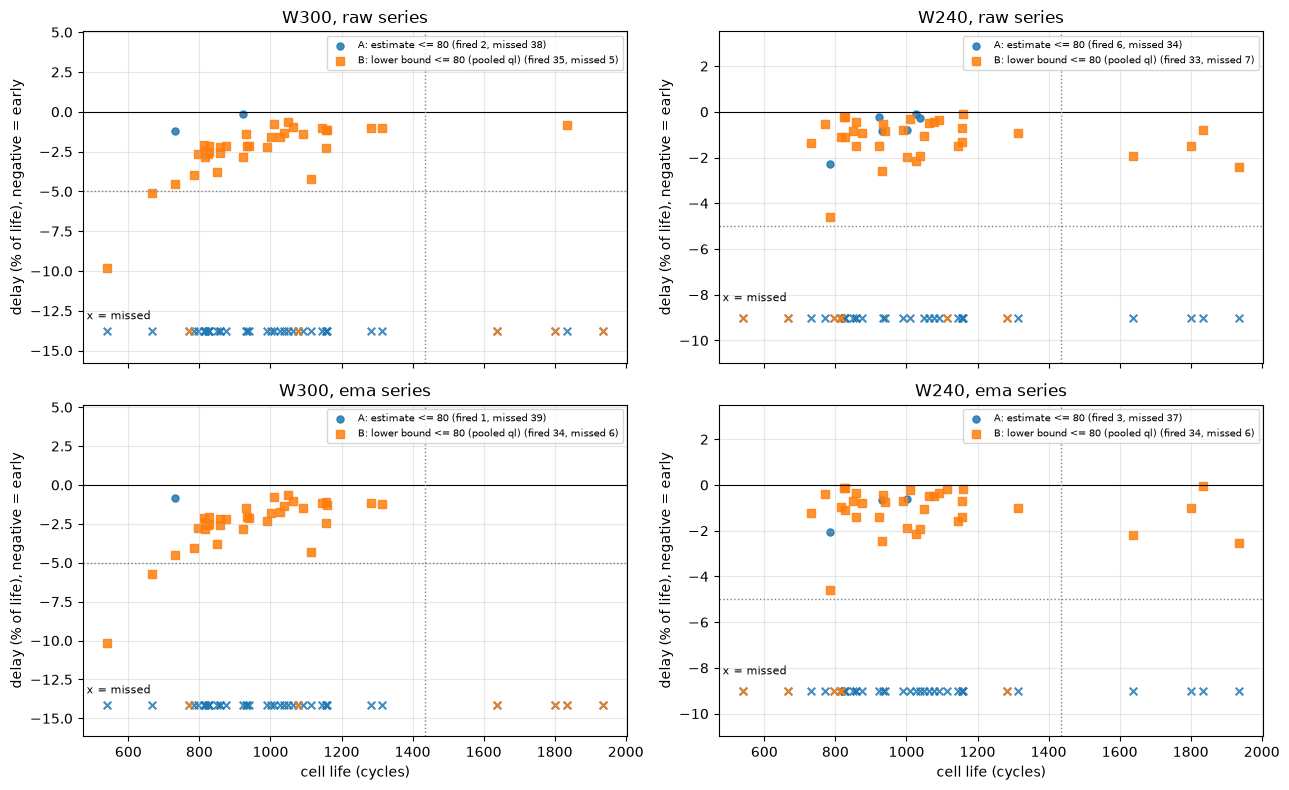

In [7]:
# S4 alerts on batch 3: M0 ensemble mean, EMA causal, parity checks first
B3T = SCR[SCR.group == "b3"].reset_index(drop=True); B3_RID = B3T.row_id.to_numpy()
PMS = PM0[PM0.cell_id.isin(set(B3C))]
PRM = {w: PMS[PMS.window.astype(str) == w].groupby("row_id").pred_pp.mean().reindex(B3_RID).to_numpy() for w in WINDOWS}
check("batch-3 M0 ensemble mean: one finite value per scored row", all(np.isfinite(PRM[w]).all() for w in WINDOWS), f"{len(B3_RID):,} scored rows, {len(B3C)} cells, NaN {sum(int(np.isnan(PRM[w]).sum()) for w in WINDOWS)}")
def ema_b3(p, a):
    out = np.empty(len(p))
    for _, ix in B3T.groupby("cell_id", sort=False).indices.items(): out[ix] = lfilter([a], [1, -(1 - a)], p[ix], zi=[(1 - a) * p[ix][0]])[0]
    return out
SER = {}
for w in WINDOWS: SER[(w, "raw")] = PRM[w]; SER[(w, "ema")] = ema_b3(PRM[w], ALPHA[w])
BIAS = {w: pd.Series(PRM[w] - B3T.y.to_numpy()).groupby(B3T.cell_id.values).mean().loc[B3C] for w in WINDOWS}   # pred - y, raw M0 ensemble mean

# --- parity: batch-3 coverage of the config conformal tables vs 07b
def b3_cov(w, kind, variant):
    est = SER[(w, kind)]; lo, hi, lowb = conf_lookup(w, kind, est, variant); y = B3T.y.to_numpy(); ins = (y >= lo) & (y <= hi)
    cc = pd.Series(ins.astype(float)).groupby(B3T.cell_id.values).mean().loc[B3C]; lc = pd.Series((y >= lowb).astype(float)).groupby(B3T.cell_id.values).mean().loc[B3C]
    return dict(window=w, series=kind, variant=variant, macro_coverage=float(cc.mean()), pooled_coverage=float(ins.mean()), lower_bound_macro_coverage=float(lc.mean()), n_cells=len(cc), n_rows=len(y))
COV = pd.DataFrame([b3_cov(w, k, v) for w in WINDOWS for k in ("raw", "ema") for v in ("pooled", "cellbal")])
_p = P7B / "s5_coverage_batch3.csv"
if SMOKE:
    check("parity: batch-3 coverage equals 07b", True, "skipped in smoke (8 cells; 07b numbers cover 40)")
else:
    if not _p.exists(): check("07b s5_coverage_batch3.csv exists", False, f"missing {_p}")
    C7 = pd.read_csv(_p); mg = COV.merge(C7[["window", "series", "variant", "macro_coverage", "pooled_coverage", "lower_bound_macro_coverage"]], on=["window", "series", "variant"], suffixes=("", "_7b"), how="left")
    dd = max(float((mg[c] - mg[c + "_7b"]).abs().max()) for c in ("macro_coverage", "pooled_coverage", "lower_bound_macro_coverage"))
    check("parity: batch-3 coverage (8 series x variants) equals 07b to 1e-9", dd <= 1e-9 and mg.macro_coverage_7b.notna().all(), f"max abs diff {dd:.2e} over {len(mg)} rows (macro, pooled and lower-bound coverage)")
    for w, ref in (("W300", 0.986), ("W240", 0.980)):
        v = float(COV[(COV.window == w) & (COV.series == "raw") & (COV.variant == "pooled")].macro_coverage.iloc[0])
        check(f"parity: {w} raw pooled macro coverage is {ref:.3f}", round(v, 3) == ref, f"observed {v:.9f}, rounds to {round(v, 3):.3f}")
show(COV, "S4a parity: batch-3 macro coverage of the two-sided 90% interval from the config conformal tables (07b numbers reproduced)", "s4a_coverage_parity.csv", 4)

# --- 85% warning: the 7b functions, life = cycle_life_final
def alerts(df, sig, thr, keys):
    if thr != 85.0: raise ValueError("alerts() with a y-crossing truth is only for the 85% warning; 80% EOL uses eol_alerts()")
    rows = []; cyc, yv, lf = df.cycle.to_numpy(), df.y.to_numpy(), df.life.to_numpy()
    for k, ix in df.groupby(keys, sort=False).indices.items():
        cr = np.flatnonzero(yv[ix] <= thr + 1e-9); fi = np.flatnonzero(sig[ix] <= thr)
        rows.append(dict(key=k, life=lf[ix][0], cross=cyc[ix][cr[0]] if len(cr) else np.nan, fire=cyc[ix][fi[0]] if len(fi) else np.nan))
    return pd.DataFrame(rows)
def alert_summary(a):
    c = a[a.cross.notna()]; n = len(c); miss = c.fire.isna(); det = c[~miss]; dl = det.fire - det.cross; pct = 100 * dl / det.life
    early = det.fire < det.cross - 0.05 * det.life
    return dict(n_cells=len(a), n_with_crossing=n, n_detected=len(det), missed_pct=100 * miss.mean() if n else np.nan, early_pct=100 * early.sum() / n if n else np.nan,
                median_abs_delay_cycles=dl.abs().median(), mean_abs_delay_cycles=dl.abs().mean(), median_abs_delay_pct_life=pct.abs().median(), mean_abs_delay_pct_life=pct.abs().mean(),
                median_signed_delay_pct_life=pct.median())
A85 = pd.DataFrame([dict(window=w, series=k, alert="85% warning", rule="A: estimate <= 85", **alert_summary(alerts(B3T, SER[(w, k)], 85.0, "cell_id"))) for w in WINDOWS for k in ("raw", "ema")])
show(A85, "S4b batch-3 85% warning, rule A (cycle_life_final; the 7b functions)", "s4b_alerts_85_batch3.csv", 2)
_p = P7B / "s5_alerts_batch3.csv"
if SMOKE:
    A85_OK, A85_DETAIL = True, "skipped in smoke (8 cells)"
else:
    if not _p.exists(): check("07b s5_alerts_batch3.csv exists", False, f"missing {_p}")
    a7 = pd.read_csv(_p); a7 = a7[(a7.alert == "85% warning") & (a7.rule == "A: estimate <= 85")]
    mg = A85.merge(a7, on=["window", "series"], suffixes=("", "_7b"), how="left"); _num = [c for c in A85.columns if c not in ("window", "series", "alert", "rule")]
    _bad = [c for c in _num if not np.allclose(mg[c].to_numpy(float), mg[c + "_7b"].to_numpy(float), rtol=0, atol=1e-9, equal_nan=True)]
    A85_OK = (not _bad) and len(a7) == len(A85) and mg[_num[0] + "_7b"].notna().all()
    _dm = [np.abs(mg[c].to_numpy(float) - mg[c + "_7b"].to_numpy(float)) for c in _num]; _dm = np.concatenate(_dm); _dm = _dm[np.isfinite(_dm)]
    A85_DETAIL = f"{len(A85)} rows vs {len(a7)} 07b rows, {len(_num)} columns compared, columns differing {_bad}, max abs diff {(_dm.max() if len(_dm) else 0.0):.2e}"
check("85% warning (rule A) with cycle_life_final is identical to 07b", A85_OK, A85_DETAIL)

# --- 80% EOL: truth = cycle_life_final; blocked until addendum_frozen is logged
EOL80_FIRST = {}
def eol_alerts(df, sig, keys):
    if not log_has("addendum_frozen"): raise PermissionError("80% alert metrics are blocked until addendum_frozen is logged")
    if not EOL80_FIRST: EOL80_FIRST.update(t_utc=now_utc(), log_events=[e["event"] for e in log_entries()])
    rows = []; cyc, lf = df.cycle.to_numpy(), df.life.to_numpy()
    for k, ix in df.groupby(keys, sort=False).indices.items():
        ok = np.flatnonzero((sig[ix] <= 80.0) & (cyc[ix] <= lf[ix]))
        rows.append(dict(key=k, life=lf[ix][0], fire=cyc[ix][ok[0]] if len(ok) else np.nan))
    return pd.DataFrame(rows)
def eol_summary(a):
    n = len(a); det = a[a.fire.notna()]; dl = det.fire - det.life; pct = 100 * dl / det.life; early = dl < -0.05 * det.life
    return dict(n_cells=n, n_fired=len(det), n_missed=n - len(det), missed_pct=100 * (n - len(det)) / n if n else np.nan, n_early=int(early.sum()), early_pct=100 * early.sum() / n if n else np.nan,
                median_abs_delay_cycles=dl.abs().median(), mean_abs_delay_cycles=dl.abs().mean(), median_abs_delay_pct_life=pct.abs().median(), mean_abs_delay_pct_life=pct.abs().mean(),
                median_signed_delay_cycles=dl.median(), median_signed_delay_pct_life=pct.median(), median_lead_cycles=(-dl).median())
RULES = {"A": "A: estimate <= 80", "B": "B: lower bound <= 80 (pooled ql)", "Bcb": "B-sens: lower bound <= 80 (cell-balanced ql)"}
def rule_signals(w, kind, est):
    return {"A": est, "B": conf_lookup(w, kind, est, "pooled")[2], "Bcb": conf_lookup(w, kind, est, "cellbal")[2]}
M80, PCL, ROWS80 = {}, {}, []
for w in WINDOWS:
    for kind in ("raw", "ema"):
        for r, sig in rule_signals(w, kind, SER[(w, kind)]).items():
            a = eol_alerts(B3T, sig, "cell_id"); a["cell_id"] = a.key; a = a.set_index("cell_id").loc[B3C]
            a["delay"] = a.fire - a.life; a["delay_pct"] = 100 * a.delay / a.life; a["bias_pp"] = BIAS[w].loc[B3C].to_numpy(); PCL[(w, kind, r)] = a
            s = eol_summary(a.reset_index()); M80[(w, kind, r)] = s; ROWS80.append(dict(window=w, series=kind, rule=RULES[r], **s))
S4B = pd.DataFrame(ROWS80)
show(S4B, "S4c batch-3 80% EOL alert metrics (truth = cycle_life_final; delay = fire - life, negative = early; abs-delay and lead columns are over cells that fired)", "s4c_alerts_80_eol_batch3.csv", 2)
check("80% EOL: every batch-3 cell has a truth (life) and is evaluated", all(M80[k]["n_cells"] == len(B3C) for k in M80), f"n_cells per row {sorted({M80[k]['n_cells'] for k in M80})}, cells {len(B3C)}")

# per-cell tables
LONG = pd.concat([v.reset_index().assign(window=k[0], series=k[1], rule=RULES[k[2]]) for k, v in PCL.items()], ignore_index=True)[["window", "series", "rule", "cell_id", "life", "fire", "delay", "delay_pct", "bias_pp"]]
LONG["life_gt_1434"] = LONG.life > 1434
EXTRA_CSV["s4d_per_cell_long.csv"] = LONG
for w in WINDOWS:
    base = pd.DataFrame(dict(cell_id=B3C, life=[LIFE[c] for c in B3C], bias_pp=BIAS[w].loc[B3C].to_numpy()))
    for kind in ("raw", "ema"):
        for r in ("A", "B"):
            t = PCL[(w, kind, r)]; base[f"{kind}_{r}_fire"] = t.fire.to_numpy(); base[f"{kind}_{r}_delay"] = t.delay.to_numpy()
    show(base.sort_values("life").reset_index(drop=True), f"S4d {w} per-cell 80% EOL alerts: life, bias (pred - y, raw M0, pp), fire cycle and delay in cycles per series and rule (blank = missed; B = pooled ql)", f"s4d_per_cell_{w}.csv", 1)
MISS = LONG[LONG.fire.isna()][["window", "series", "rule", "cell_id", "life", "bias_pp", "life_gt_1434"]].sort_values(["window", "series", "rule", "life"]).reset_index(drop=True)
EXTRA_CSV["s4e_missed_cells_all_rules.csv"] = MISS
show(MISS[MISS.rule.isin([RULES["A"], RULES["B"]])].reset_index(drop=True), "S4e missed cells, rules A and B pooled (never fired at a cycle <= life): life and bias; cell-balanced sensitivity is in s4e_missed_cells_all_rules.csv", "s4e_missed_cells.csv", 2)

# figure: delay (% of life) vs cell life, rules A and B
fig, axs = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for i, kind in enumerate(("raw", "ema")):
    for j, w in enumerate(WINDOWS):
        ax = axs[i, j]; allv = np.concatenate([PCL[(w, kind, r)].delay_pct.dropna().to_numpy() for r in ("A", "B")]); ymiss = min(float(allv.min()) if len(allv) else 0.0, -5.0) - 4.0
        for r, mk, col in (("A", "o", "tab:blue"), ("B", "s", "tab:orange")):
            t = PCL[(w, kind, r)]; f = t.fire.notna()
            ax.scatter(t.life[f], t.delay_pct[f], marker=mk, s=26, color=col, alpha=.85, label=f"{RULES[r]} (fired {int(f.sum())}, missed {int((~f).sum())})")
            ax.scatter(t.life[~f], np.full(int((~f).sum()), ymiss), marker="x", s=30, color=col, alpha=.85)
        ax.axhline(0, color="k", lw=.8); ax.axhline(-5, color="grey", ls=":", lw=1); ax.axvline(1434, color="grey", ls=":", lw=1); ax.text(ax.get_xlim()[0], ymiss + 0.6, " x = missed", fontsize=8, va="bottom")
        _hi = max(float(allv.max()) if len(allv) else 0.0, 0.0); _lo = ymiss - 2.0; ax.set_ylim(_lo, _hi + 0.32 * (_hi - _lo))
        ax.set_title(f"{w}, {kind} series"); ax.set_ylabel("delay (% of life), negative = early"); ax.grid(alpha=.3); ax.legend(fontsize=7, loc="upper right")
for ax in axs[1]: ax.set_xlabel("cell life (cycles)")
fig.tight_layout(); fig.savefig(W(OUT / "fig_delay_vs_life.png"), dpi=130); plt.show()

**S5** development reference (in-sample calibration)

In [8]:
# S5 development reference for the same functions (non-stitched cells, out-of-fold M0 ensemble mean; calibration tables are IN-SAMPLE here)
def build_dev(w):
    f = FIN[FIN.window.astype(str) == w]
    g = f.groupby(["repeat", "row_id"]).agg(pred=("pred_pp", "mean"), nseed=("seed", "nunique"), cell_id=("cell_id", "first")).reset_index()
    g["cycle"] = LAB_IDX.loc[g.row_id, "cycle_number"].to_numpy().astype(float); g["scored"] = LAB_IDX.loc[g.row_id, "scored2"].to_numpy()
    g = g[g.scored].copy(); g["y"] = YS.reindex(g.row_id).to_numpy(); g["life"] = g.cell_id.map(LIFE)
    return g.sort_values(["repeat", "cell_id", "cycle", "row_id"]).reset_index(drop=True)
def ema_dev(df, a):
    out = np.empty(len(df)); p = df.pred.to_numpy()
    for _, ix in df.groupby(["repeat", "cell_id"], sort=False).indices.items(): out[ix] = lfilter([a], [1, -(1 - a)], p[ix], zi=[(1 - a) * p[ix][0]])[0]
    return out
DEV = {}
for w in WINDOWS:
    g = build_dev(w); check(f"{w} dev OOF: finite y, pred, life; 5 seeds per row", np.isfinite(g[["y", "pred", "life"]].to_numpy()).all() and (g.nseed == 5).all(), f"{len(g):,} scored rows, {g.cell_id.nunique()} cells, {g.repeat.nunique()} repeats, seeds per row {int(g.nseed.min())}-{int(g.nseed.max())}")
    g = g[~g.cell_id.isin(STITCHED)].reset_index(drop=True); g["ema"] = ema_dev(g, ALPHA[w]); DEV[w] = g
    check(f"{w} dev OOF: non-stitched cells only", g.cell_id.nunique() == len(NONSTITCH) and not g.cell_id.isin(STITCHED).any(), f"{g.cell_id.nunique()} cells, {g.repeat.nunique()} repeats")
def dev_row(w, kind, label, a, summ):
    a = a.copy(); a["repeat"] = [k[0] for k in a.key]
    m = pd.DataFrame([summ(g) for _, g in a.groupby("repeat")]).mean(numeric_only=True)
    return dict(window=w, series=kind, alert=label, n_cells=int(m.n_cells), n_repeats=int(a.repeat.nunique()), **{k: v for k, v in m.items() if k != "n_cells"})
DROWS = []
for w in WINDOWS:
    d = DEV[w]
    for kind, col in (("raw", "pred"), ("ema", "ema")):
        est = d[col].to_numpy()
        DROWS.append(dev_row(w, kind, "85% rule A", alerts(d, est, 85.0, ["repeat", "cell_id"]), alert_summary))
        for r, lab in (("A", "80% EOL rule A"), ("B", "80% EOL rule B (pooled)"), ("Bcb", "80% EOL rule B (cell-balanced)")):
            DROWS.append(dev_row(w, kind, lab, eol_alerts(d, rule_signals(w, kind, est)[r], ["repeat", "cell_id"]), eol_summary))
DEVT = pd.DataFrame(DROWS)
show(DEVT, f"S5a development out-of-fold reference ({len(NONSTITCH)} non-stitched cells, life = cycle_life_final; metrics per repeat then averaged over repeats; conformal tables are IN-SAMPLE here)", "s5a_dev_reference.csv", 2)
REF = pd.DataFrame([dict(window="W300", alert="80% EOL rule A", ref_missed_pct=63.7, ref_early_pct=1.3, ref_mean_abs_delay_pct_life=1.4, ref_median_signed_delay_cycles=np.nan),
                    dict(window="W300", alert="80% EOL rule B (pooled)", ref_missed_pct=7.2, ref_early_pct=30.0, ref_mean_abs_delay_pct_life=4.4, ref_median_signed_delay_cycles=np.nan),
                    dict(window="W240", alert="80% EOL rule A", ref_missed_pct=52.3, ref_early_pct=0.0, ref_mean_abs_delay_pct_life=0.5, ref_median_signed_delay_cycles=np.nan),
                    dict(window="W240", alert="80% EOL rule B (pooled)", ref_missed_pct=7.6, ref_early_pct=0.8, ref_mean_abs_delay_pct_life=2.2, ref_median_signed_delay_cycles=-12.0),
                    dict(window="W300", alert="85% rule A", ref_missed_pct=1.3, ref_early_pct=3.8, ref_mean_abs_delay_pct_life=2.4, ref_median_signed_delay_cycles=np.nan),
                    dict(window="W240", alert="85% rule A", ref_missed_pct=1.3, ref_early_pct=0.0, ref_mean_abs_delay_pct_life=1.2, ref_median_signed_delay_cycles=np.nan)])
OBS = DEVT[DEVT.series == "raw"].set_index(["window", "alert"])
CMPR = REF.copy()
CMPR["obs_missed_pct"] = [OBS.loc[(r.window, r.alert), "missed_pct"] for r in REF.itertuples()]; CMPR["obs_early_pct"] = [OBS.loc[(r.window, r.alert), "early_pct"] for r in REF.itertuples()]
CMPR["obs_mean_abs_delay_pct_life"] = [OBS.loc[(r.window, r.alert), "mean_abs_delay_pct_life"] for r in REF.itertuples()]
CMPR["obs_median_signed_delay_cycles"] = [OBS.loc[(r.window, r.alert), "median_signed_delay_cycles"] if "median_signed_delay_cycles" in OBS.columns else np.nan for r in REF.itertuples()]
CMPR["missed_diff_pts"] = CMPR.obs_missed_pct - CMPR.ref_missed_pct
show(CMPR, "S5b development reference vs the 6b reference (raw series; 6b given as in the task; WARN when missed% differs by more than 5 points)", "s5b_dev_vs_6b.csv", 2)
for r in CMPR.itertuples():
    check(f"6b reference: {r.window} {r.alert} missed% within 5 points", abs(r.missed_diff_pts) <= 5, f"observed {r.obs_missed_pct:.1f}% vs 6b {r.ref_missed_pct:.1f}% (diff {r.missed_diff_pts:+.1f} points); early {r.obs_early_pct:.1f}% vs {r.ref_early_pct:.1f}%; mean abs delay {r.obs_mean_abs_delay_pct_life:.2f}% vs {r.ref_mean_abs_delay_pct_life:.1f}% of life", warn_only=True)

[PASS] W300 dev OOF: finite y, pred, life; 5 seeds per row - 167,889 scored rows, 84 cells, 3 repeats, seeds per row 5-5
[PASS] W300 dev OOF: non-stitched cells only - 79 cells, 3 repeats
[PASS] W240 dev OOF: finite y, pred, life; 5 seeds per row - 167,889 scored rows, 84 cells, 3 repeats, seeds per row 5-5
[PASS] W240 dev OOF: non-stitched cells only - 79 cells, 3 repeats

S5a development out-of-fold reference (79 non-stitched cells, life = cycle_life_final; metrics per repeat then averaged over repeats; conformal tables are IN-SAMPLE here)  (n=16 rows)
window series                          alert  n_cells  n_repeats  n_with_crossing  n_detected  missed_pct  early_pct  median_abs_delay_cycles  mean_abs_delay_cycles  median_abs_delay_pct_life  mean_abs_delay_pct_life  median_signed_delay_pct_life  n_fired  n_missed  n_early  median_signed_delay_cycles  median_lead_cycles
  W300    raw                     85% rule A       79          3            79.00       78.00        1.27       3.80

**S6** expectations vs observed

In [9]:
# S6 expectations (written in S3 before any 80% metric) vs observation; nothing is selected on this
def _m(w, k, r): return M80[(w, k, r)]
S6 = []
b = _m("W240", "raw", "B"); ok5 = bool(b["missed_pct"] <= 15 and b["median_signed_delay_pct_life"] >= -5)
S6.append(dict(id="H5", expected=EXPECT["H5"], observed=f"W240 rule B raw: missed {b['missed_pct']:.1f}% ({b['n_missed']} of {b['n_cells']}), median signed delay {b['median_signed_delay_pct_life']:+.2f}% of life ({b['median_signed_delay_cycles']:+.0f} cycles), early alarms {b['early_pct']:.1f}%", consistent=ok5))
a3, a2 = _m("W300", "raw", "A"), _m("W240", "raw", "A"); ok6 = bool(a3["missed_pct"] >= 30 and a2["missed_pct"] >= 30)
S6.append(dict(id="H6", expected=EXPECT["H6"], observed=f"rule A raw missed: W300 {a3['missed_pct']:.1f}% ({a3['n_missed']} of {a3['n_cells']}), W240 {a2['missed_pct']:.1f}% ({a2['n_missed']} of {a2['n_cells']})", consistent=ok6))
lg = [c for c in B3C if LIFE[c] > 1434]; ms = {r: int(PCL[("W300", "raw", r)].loc[lg, "fire"].isna().sum()) for r in ("A", "B")} if lg else {}
ok7 = bool(all(ms[r] > len(lg) / 2 for r in ("A", "B"))) if lg else "n/a"
S6.append(dict(id="H7", expected=EXPECT["H7"], observed=(f"W300 raw, {len(lg)} cells above 1434: missed under rule A {ms['A']}, under rule B {ms['B']}" if lg else "no batch-3 cell above 1434 cycles in this run"), consistent=ok7))
S6T = show(pd.DataFrame(S6), "S6 expectations (fixed before any 80% alert metric) vs observed; nothing is selected on this", "s6_expectations.csv")
EXTRA["s6"] = S6


S6 expectations (fixed before any 80% alert metric) vs observed; nothing is selected on this  (n=3 rows)
id                                                                                                                               expected                                                                                                   observed  consistent
H5 Rule B (raw series, pooled ql) at W240 misses at most 15% of batch-3 cells and its median signed delay is no earlier than -5% of life. W240 rule B raw: missed 17.5% (7 of 40), median signed delay -0.91% of life (-9 cycles), early alarms 0.0%       False
H6                                                              Rule A (raw series) at both windows misses at least 30% of batch-3 cells.                                            rule A raw missed: W300 95.0% (38 of 40), W240 85.0% (34 of 40)        True
H7        At W300 (raw series), more than half of the batch-3 cells above 1,434 cycles are missed under rule A and under ru

**S7** report and artifacts

In [10]:
# S7 report and artifacts
HASHES_END = verify_frozen("end")
check("monitor_config.json unchanged (start vs end)", HASHES_END["monitor_config"]["got"] == CFG_SHA == FROZEN["monitor_config"][1], f"sha256 {CFG_SHA[:16]}...")
check("addendum unchanged since it was logged", sha256_file(ADD_PATH) == ADD_SHA, f"sha256 {ADD_SHA[:16]}...")
check("expectations unchanged since they were logged", sha256_file(EXP_PATH) == EXP_SHA, f"sha256 {EXP_SHA[:16]}...")
_ev = log_entries(); _names = [e["event"] for e in _ev]; _ia = max(i for i, n in enumerate(_names) if n == "addendum_frozen"); _ea = _ev[_ia]
check("addendum logged before any 80% alert metric", bool(EOL80_FIRST) and "addendum_frozen" in EOL80_FIRST["log_events"] and EOL80_FIRST["t_utc"] >= _ea["t_utc"], f"first 80% metric at {EOL80_FIRST.get('t_utc')} with log events {EOL80_FIRST.get('log_events')}; addendum_frozen logged at {_ea['t_utc']}")
check("85% numbers identical to 07b", A85_OK, A85_DETAIL)
EXTRA.update(dict(hashes_start=HASHES_START, hashes_end=HASHES_END, monitor_config_sha256=CFG_SHA, addendum_sha256=ADD_SHA, expectations_sha256=EXP_SHA, life_column="cycle_life_final",
                  dev_cells_life_gt_1434=dict(n=N_DEV_LONG, cells=_dl.cell_id.tolist(), lives=_dl.cycle_life_final.tolist(), n_by_cycle_life_field=N_DEV_LONG_FIELD), stitched_cells=sorted(STITCHED), alpha=ALPHA,
                  eol80_metrics={f"{k[0]}|{k[1]}|{k[2]}": v for k, v in M80.items()}, cells_batch3=len(B3C)))
log_append("done", elapsed_s=round(time.time() - T0, 1), addendum_sha256=ADD_SHA, monitor_config_sha256=CFG_SHA)
_ev = log_entries(); _lines = _log_lines()
_names = [e["event"] for e in _ev]
_chain_ok = all(_ev[i]["prev_line_sha256"] == (sha256_bytes(_lines[i - 1].encode("utf-8")) if i else "") for i in range(len(_ev)))
_order_ok = _names[0] == "start" and _names[-1] == "done" and "addendum_frozen" in _names and _names.index("addendum_frozen") > _names.index("start")
check("phase7b2 log: hash chain intact; start, addendum_frozen, done in order", _chain_ok and _order_ok, f"{len(_ev)} events {_names}, chain links valid {sum(_ev[i]['prev_line_sha256'] == (sha256_bytes(_lines[i - 1].encode('utf-8')) if i else '') for i in range(len(_ev)))}")
for nm, df in TABLES.items(): df.to_csv(W(OUT / nm), index=False)
for nm, df in EXTRA_CSV.items(): df.to_csv(W(OUT / nm), index=False)

REPORT, VERIF = OUT / "phase7b2_report.txt", OUT / "verification_report.json"
def _artifacts():
    rows = []
    for p in sorted(OUT.rglob("*")):
        if not p.is_file() or (not SMOKE and p.relative_to(OUT).parts[0] == "smoke"): continue
        late = p in (REPORT, VERIF)
        rows.append(dict(path=str(p.relative_to(ROOT)), size_kb=np.nan if late else round(p.stat().st_size / 1024, 1), note="written after this table" if late else ""))
    for p in (REPORT, VERIF):
        if not any(r["path"] == str(p.relative_to(ROOT)) for r in rows): rows.append(dict(path=str(p.relative_to(ROOT)), size_kb=np.nan, note="written after this table"))
    return pd.DataFrame(rows)
show(_artifacts(), "Artifacts", None, 1)
def build_report():
    L = ["PHASE 7b2 - 80% END-OF-LIFE ALERT PATCH" + (" (SMOKE RUN - DO NOT QUOTE)" if SMOKE else ""), "=" * 78, "",
         "Batch 3 is spent; every batch-3 number below is descriptive. Life column = cycle_life_final. 80% EOL truth = cycle_life_final (no y <= 80 crossing).",
         f"monitor_config.json sha256 {CFG_SHA} (unchanged)", f"monitor_config_addendum.json sha256 {ADD_SHA}", f"EMA alpha (read from the config): {ALPHA}", f"runtime {(time.time() - T0) / 60:.1f} min", ""]
    for b in BLOCKS: L += [b["text"], ""]
    L += ["CHECKS", "-" * 78] + [f"[{c['status']}] {c['name']} - {c['detail']}" for c in CHECKS]
    return "\n".join(L) + "\n"
write_text(REPORT, build_report())
_rep = REPORT.read_text(encoding="utf-8"); _miss = [b["title"] for b in BLOCKS if b["kind"] == "table" and b["title"] not in _rep]
check("every printed table is in the report", not _miss, f"{sum(b['kind'] == 'table' for b in BLOCKS)} tables printed, {len(_miss)} missing from the report {_miss}")
write_text(REPORT, build_report())
_n = dump_report()
print(f"\nreport {REPORT.stat().st_size / 1024:.1f} KB | verification_report.json {VERIF.stat().st_size / 1024:.1f} KB")
print(f"PASS {_n['PASS']} | WARN {_n['WARN']} | FAIL {_n['FAIL']} | runtime {(time.time() - T0) / 60:.1f} min" + (" | SMOKE: do not quote" if SMOKE else ""))

[PASS] [end] sha256 monitor_config - monitor_config.json: got 638b6c3a6ad31c69... expected 638b6c3a6ad31c69...
[PASS] [end] sha256 preregistration - preregistration.json: got 11f9741387cb001e... expected 11f9741387cb001e...
[PASS] [end] sha256 batch3_predictions - batch3_predictions.parquet: got 679ec76862de63f2... expected 679ec76862de63f2...
[PASS] [end] sha256 batch3_verdict - batch3_verdict.json: got 57a054bdf25243d3... expected 57a054bdf25243d3...
[PASS] [end] sha256 model_M0_W240 - M0_W240.npz: got 29cd3ec8c5c2113d... expected 29cd3ec8c5c2113d...
[PASS] [end] sha256 model_M0_W300 - M0_W300.npz: got 06f63dc6c5a89750... expected 06f63dc6c5a89750...
[PASS] monitor_config.json unchanged (start vs end) - sha256 638b6c3a6ad31c69...
[PASS] addendum unchanged since it was logged - sha256 d842e5f4c3186889...
[PASS] expectations unchanged since they were logged - sha256 8201a667fb3686f3...
[PASS] addendum logged before any 80% alert metric - first 80% metric at 2026-11-05T04:59:08+00:00 wi